# 13 · Discrete counterfactuals: declared couplings, sharp bounds, calibrated sets

Ground truth (one MDP transition, ordered health levels 0 < 1 < 2):

    treatment a in {0: none, 1: mild, 2: strong}  ~ uniform (logged policy)
    health'   ~ P(. | a)                          (true table below)

A patient got no treatment (`a = 0`) and ended in health 0.  Would the strong
treatment have helped?  Data identify only `P(health' | a)`, so the answer
depends on how the noise couples different treatments.  We show:

1. Two declared couplings (Gumbel-max, monotone) with a neural kernel: two
   different point answers from the same fitted kernel.
2. The bounds that hold for every SCM with that kernel: both answers inside.
3. Bounds that also cover estimation error (a confidence box on the kernel).
4. Calibration of the kernel itself: a randomized-PIT band and conformal
   prediction sets on held-out data.
5. Which conformal score to use when the classifier is very confident.

- **NBN API:** `nbn.scm.StructuralNeuralCategorical`, `StructuralCategoricalTable`,
  `counterfactual_sample`, `counterfactual_bounds`, `counterfactual_bounds_from_sets`,
  `pit_band_set`, `calibration_by_bins_test`, `conformal_sets` (`score="exclusive"`, `"inclusive"`, `"randomized"`); `nbn.uncertainty.interval_set`.
- **Runtime:** under 30 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

In [1]:
import os

import matplotlib.pyplot as plt
import torch

from nbn.scm import (
    StructuralCategoricalTable,
    StructuralCausalModel,
    StructuralNeuralCategorical,
    calibration_by_bins_test,
    conformal_sets,
    counterfactual_bounds_from_sets,
    pit_band_set,
)
from nbn.uncertainty import interval_set  # entry-wise PAC intervals on P(h | a), all entries at once
from nbn.utils.device import resolve_device

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
                     "font.size": 9})


def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## The data

3000 training rows and 1500 held-out rows, each from its own generator.

In [2]:
torch.manual_seed(0)
TRUE = torch.tensor([[0.60, 0.30, 0.10],   # a = 0
                     [0.30, 0.45, 0.25],   # a = 1
                     [0.10, 0.30, 0.60]])  # a = 2


def simulate(n: int, seed: int) -> dict:
    gen = torch.Generator().manual_seed(seed)
    a = torch.randint(0, 3, (n,), generator=gen)
    h = torch.multinomial(TRUE[a], 1, generator=gen).reshape(-1)
    return {"a": a.float().unsqueeze(-1), "h": h.float().unsqueeze(-1)}


train, held_out = simulate(3000, seed=1), simulate(1500, seed=2)

## 1. One kernel, two declared couplings

We fit the kernel `P(h | a)` once.  The coupling is a declared reading of it,
not something learned: Gumbel-max and monotone couplings give different
counterfactual answers from the same kernel.

In [3]:
model = StructuralCausalModel([("a", "h")], {"a": ("discrete", 3), "h": ("discrete", 3)}, device=device)
model.set_mechanism("a", StructuralCategoricalTable())
model.set_mechanism("h", StructuralNeuralCategorical(n_classes=3, hidden=(32,), coupling="monotone"))
model.fit(train)
mech = model.mechanisms["h"]

evidence = {"a": torch.zeros(20000, 1), "h": torch.zeros(20000, 1)}   # untreated, ended in 0
answers = {}
print("Counterfactual P(health' = k | did a=0 and got 0, had we done a=2):")
for coupling in ("gumbel_max", "monotone"):
    model.set_mechanism("h", mech.with_coupling(coupling))
    world = model.counterfactual_sample(evidence, do={"a": 2.0})["h"][0, :, 0].long()
    answers[coupling] = torch.bincount(world, minlength=3).float().cpu() / 20000
    print(f"  {coupling:>10}: {answers[coupling].numpy().round(3)}")
mech = model.mechanisms["h"]

Counterfactual P(health' = k | did a=0 and got 0, had we done a=2):
  gumbel_max: [0.204 0.149 0.646]
    monotone: [0.208 0.454 0.338]


## 2. Bounds over every compatible SCM

`counterfactual_bounds` gives the sharp bounds over all SCMs that share the
fitted kernel: any coupling's answer lies inside.

In [4]:
with torch.no_grad():
    lo, hi = mech.counterfactual_bounds(torch.zeros(1, 1), torch.zeros(1, 1), torch.full((1, 1), 2.0))
print(f"  every compatible SCM lies in  lower {lo[0].cpu().numpy().round(3)}  upper {hi[0].cpu().numpy().round(3)}")
print("  (both answers lie inside, up to Monte-Carlo error of about 0.005)")

  every compatible SCM lies in  lower [0.    0.    0.338]  upper [0.209 0.453 0.955]
  (both answers lie inside, up to Monte-Carlo error of about 0.005)


## 3. Estimation error too

A 95% box on every entry of `P(h | a)` (rows = `a`), then the bounds over every
kernel in that box (`counterfactual_bounds_from_sets`).

In [5]:
q_lo, q_hi = interval_set(model, train, "h", delta=0.05).bounds()
lo_s, hi_s = counterfactual_bounds_from_sets(q_lo[0:1], q_lo[2:3], q_hi[2:3], torch.tensor([0]))
print(f"  ... and every kernel in a 95% box: lower {lo_s[0].cpu().numpy().round(3)}  upper {hi_s[0].cpu().numpy().round(3)}")

  ... and every kernel in a 95% box: lower [0.    0.    0.185]  upper [0.295 0.582 1.   ]


Left: the fitted kernel and its 95% box against the true table.  Right: the
counterfactual answer.  The two couplings give two points; the dark range holds
for every SCM with the fitted kernel, the light range also allows for
estimation error.

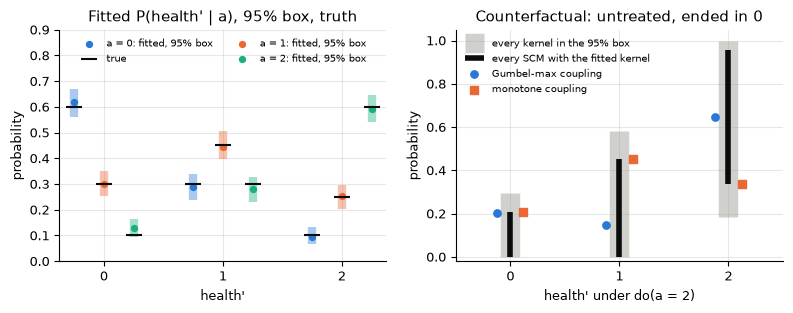

In [6]:
with torch.no_grad():
    fitted = mech.probs(torch.tensor([[0.0], [1.0], [2.0]]).to(device)).cpu()
classes = range(3)
fig, (ax_k, ax_cf) = plt.subplots(1, 2, figsize=(8, 3.2))
for i, (a, color) in enumerate(zip(range(3), (BLUE, ORANGE, AQUA))):
    x = [k + (i - 1) * 0.25 for k in classes]
    ax_k.vlines(x, to_numpy(q_lo[a]), to_numpy(q_hi[a]), color=color, lw=6, alpha=0.4)
    ax_k.scatter(x, to_numpy(fitted[a]), color=color, s=18, zorder=3, label=f"a = {a}: fitted, 95% box")
    ax_k.scatter(x, to_numpy(TRUE[a]), color=INK, marker="_", s=120, zorder=4,
                 label="true" if a == 0 else None)
ax_k.set(xticks=list(classes), xlabel="health'", ylabel="probability",
         title="Fitted P(health' | a), 95% box, truth")
ax_k.set_ylim(0, 0.9)
ax_k.legend(frameon=False, fontsize=7, loc="upper center", ncol=2)

ks = list(classes)
ax_cf.vlines(ks, to_numpy(lo_s[0]), to_numpy(hi_s[0]), color=GREY, lw=14,
             alpha=0.5, label="every kernel in the 95% box")
ax_cf.vlines(ks, to_numpy(lo[0]), to_numpy(hi[0]), color=INK, lw=4,
             label="every SCM with the fitted kernel")
ax_cf.scatter([k - 0.12 for k in ks], to_numpy(answers["gumbel_max"]), color=BLUE, s=28, zorder=3,
              label="Gumbel-max coupling")
ax_cf.scatter([k + 0.12 for k in ks], to_numpy(answers["monotone"]), color=ORANGE, s=28, zorder=3,
              marker="s", label="monotone coupling")
ax_cf.set(xticks=ks, xlim=(-0.5, 2.5), xlabel="health' under do(a = 2)", ylabel="probability", ylim=(-0.02, 1.05),
          title="Counterfactual: untreated, ended in 0")
ax_cf.legend(frameon=False, fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()

## 4. Calibration of the fitted kernel on held-out rows

The randomized PIT of a correct kernel is uniform on (0, 1).  `pit_band_set`
puts a 95% DKW band on its CDF; if the PIT does not depend on `a`, the band
bounds `P(health' <= k | a)` for every `a`.  `calibration_by_bins_test` checks
calibration within bins of the prediction, and `conformal_sets` gives
prediction sets with 80% marginal coverage.

In [7]:
gen = torch.Generator().manual_seed(0)
band = pit_band_set(model, held_out, "h", delta=0.05, generator=gen)
cdf_lo, cdf_hi = band.cdf_bounds(mech, torch.zeros(3, 1), torch.tensor([[0.0], [1.0], [2.0]]))
print("P(health' <= 0 | a) with a 95% band (if the PIT does not depend on a):")
for a in range(3):
    print(f"  a={a}: [{float(cdf_lo[a]):.3f}, {float(cdf_hi[a]):.3f}]   truth {float(TRUE[a, 0]):.3f}")
print("calibration by bins, p-value:",
      round(calibration_by_bins_test(model, held_out, "h", n_bins=3, generator=gen).p_value, 3))
sets = conformal_sets(model, held_out, "h", alpha=0.2).sets(mech, torch.tensor([[0.0], [1.0], [2.0]]))
print("80% conformal prediction sets per treatment:", [torch.nonzero(s).flatten().tolist() for s in sets])

P(health' <= 0 | a) with a 95% band (if the PIT does not depend on a):
  a=0: [0.573, 0.643]   truth 0.600
  a=1: [0.241, 0.311]   truth 0.300
  a=2: [0.082, 0.152]   truth 0.100
calibration by bins, p-value: 0.185
80% conformal prediction sets per treatment: [[0, 1], [0, 1], [1, 2]]


Left: histogram of the held-out PIT values; a calibrated kernel gives a flat
histogram.  Right: their empirical CDF with the 95% DKW band; the uniform CDF
(the diagonal) should lie inside the band.

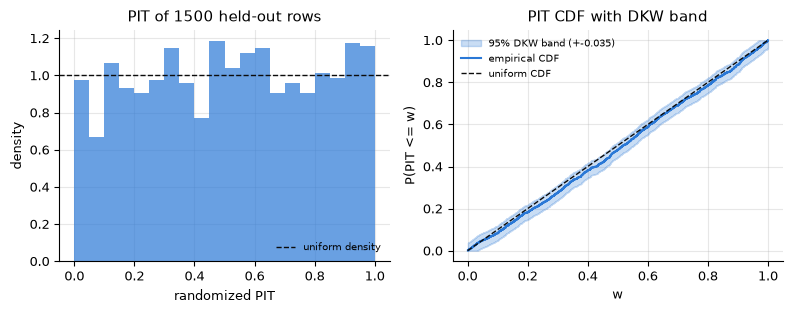

In [8]:
pit = to_numpy(band.sorted_pit)
n = len(pit)
fig, (ax_h, ax_c) = plt.subplots(1, 2, figsize=(8, 3.2))
ax_h.hist(pit, bins=20, range=(0, 1), density=True, color=BLUE, alpha=0.7)
ax_h.axhline(1.0, color=INK, lw=1, ls="--", label="uniform density")
ax_h.set(xlabel="randomized PIT", ylabel="density", title=f"PIT of {n} held-out rows")
ax_h.legend(frameon=False, fontsize=7, loc="lower right")
ecdf = [(i + 1) / n for i in range(n)]
ax_c.fill_between(pit, [max(e - band.epsilon, 0) for e in ecdf], [min(e + band.epsilon, 1) for e in ecdf],
                  step="post", color=BLUE, alpha=0.25, label=f"95% DKW band (+-{band.epsilon:.3f})")
ax_c.step(pit, ecdf, where="post", color=BLUE, lw=1.5, label="empirical CDF")
ax_c.plot([0, 1], [0, 1], color=INK, lw=1, ls="--", label="uniform CDF")
ax_c.set(xlabel="w", ylabel="P(PIT <= w)", title="PIT CDF with DKW band")
ax_c.legend(frameon=False, fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()

## 5. Conformal sets when the classifier is very confident

`conformal_sets` ranks the classes by decreasing probability.  The **score** of
the observed class is the mass of the classes ranked above it, plus `u` times
its own probability.  The threshold is a quantile of the scores on held-out
rows, and the set keeps every class scoring at most the threshold.  Every
choice of `u` gives marginal coverage of at least `1 - alpha`:

- `score="exclusive"` (`u = 0`, the default): the top class scores exactly 0,
  so a set is never empty;
- `score="inclusive"` (`u = 1`, the cumulative score of Kochenderfer et al.,
  *Algorithms for Validation*, Ex. 12.4);
- `score="randomized"` (`u` uniform on (0, 1), Romano, Sesia & Candès, NeurIPS
  2020): ties are broken, so coverage is close to `1 - alpha`.

They differ when probabilities **saturate**.  We fit a neural classifier to a
nearly deterministic child, `d = [x + V > 0]` with `V ~ N(0, 0.2²)`, where most
rows are predicted with probability 1 up to float precision (NBN issue #322).
Then we calibrate each score on 40 independent held-out samples and look at
coverage and set size on fresh rows.

In [9]:
def saturating_data(n: int, seed: int) -> dict:
    g = torch.Generator().manual_seed(seed)
    x = 2 * torch.randn(n, generator=g)
    v = 0.2 * torch.randn(n, generator=g)
    return {"x": x.unsqueeze(-1).to(device), "d": (x + v > 0).float().unsqueeze(-1).to(device)}


torch.manual_seed(0)
clf = StructuralCausalModel([("x", "d")], {"x": ("continuous", 1), "d": ("discrete", 2)}, device=device)
clf.auto_mechanisms()
clf.set_mechanism("d", StructuralNeuralCategorical(n_classes=2, hidden=(16,)))
clf.fit(saturating_data(4000, seed=0))
d_mech, fresh = clf.mechanisms["d"], saturating_data(4000, seed=1)

ALPHA, SPLITS, SCORES = 0.1, 40, ("exclusive", "inclusive", "randomized")
stats = {s: {"coverage": [], "size": [], "empty": []} for s in SCORES}
for r in range(SPLITS):
    held = saturating_data(500, seed=100 + r)
    for score in SCORES:
        gen = torch.Generator().manual_seed(r)
        cs = conformal_sets(clf, held, "d", alpha=ALPHA, score=score, generator=gen)
        sets = cs.sets(d_mech, fresh["x"], generator=gen).cpu()
        stats[score]["coverage"].append(float(sets.gather(-1, fresh["d"].long().cpu()).float().mean()))
        stats[score]["size"].append(float(sets.sum(-1).float().mean()))
        stats[score]["empty"].append(float((sets.sum(-1) == 0).float().mean()))
for score in SCORES:
    mean = {k: sum(v) / SPLITS for k, v in stats[score].items()}
    print(f"{score:10s} coverage {mean['coverage']:.3f}   mean set size {mean['size']:.3f}   "
          f"empty sets {mean['empty']:.1%}")

exclusive  coverage 0.967   mean set size 1.000   empty sets 0.0%
inclusive  coverage 0.902   mean set size 0.935   empty sets 6.5%
randomized coverage 0.896   mean set size 0.996   empty sets 9.2%


**Figure.** Each dot is one of the 40 calibration samples (500 rows each),
evaluated on the same 4000 fresh rows; the bar is the mean over the 40.
Left: coverage, with the target `1 - alpha = 0.9` dashed.  Right: share of fresh
rows whose set is empty, has one class, or has both (mean over the 40).  With saturated
probabilities the inclusive score leaves the most confident rows with an
**empty** set; the exclusive score always returns one class and over-covers
(ties at 0); the randomized score is closest to 0.9 but its sets can be empty.

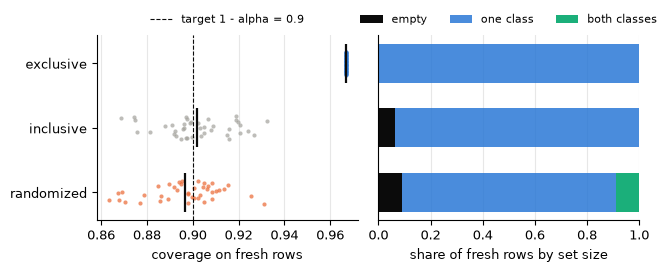

In [10]:
colors = {"exclusive": BLUE, "inclusive": GREY, "randomized": ORANGE}
fig, (ax_cov, ax_size) = plt.subplots(1, 2, figsize=(7.0, 2.4), sharey=True,
                                      gridspec_kw={"width_ratios": [1, 1], "wspace": 0.08})
jitter = torch.linspace(-0.18, 0.18, SPLITS).tolist()
for i, score in enumerate(SCORES):
    cov = stats[score]["coverage"]
    ax_cov.scatter(cov, [i + j for j in jitter], s=9, color=colors[score], alpha=0.7, linewidths=0)
    ax_cov.vlines(sum(cov) / SPLITS, i - 0.3, i + 0.3, color=INK, lw=1.6)
ax_cov.axvline(1 - ALPHA, color=INK, lw=0.8, ls="--", label=f"target 1 - alpha = {1 - ALPHA:.1f}")
ax_cov.set(yticks=range(3), yticklabels=SCORES, xlabel="coverage on fresh rows")
ax_cov.invert_yaxis()
ax_cov.grid(axis="y", visible=False)
ax_cov.legend(frameon=False, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0))

empty = [sum(stats[s]["empty"]) / SPLITS for s in SCORES]
size = [sum(stats[s]["size"]) / SPLITS for s in SCORES]
two = [max(0.0, sz - (1 - e)) for sz, e in zip(size, empty)]       # mean size = P(one) + 2 P(both)
one = [1 - e - t for e, t in zip(empty, two)]
y = list(range(3))
ax_size.barh(y, empty, height=0.6, color=INK, label="empty")
ax_size.barh(y, one, height=0.6, left=empty, color=BLUE, alpha=0.85, label="one class")
ax_size.barh(y, two, height=0.6, left=[e + o for e, o in zip(empty, one)], color=AQUA, label="both classes")
ax_size.set(xlim=(0, 1), xlabel="share of fresh rows by set size")
ax_size.grid(axis="y", visible=False)
ax_size.tick_params(axis="y", length=0)
ax_size.legend(frameon=False, fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.show()